# Customer Segmentation with K-Means

This notebook compares cluster counts, fits a K-Means model, and saves the results and charts for review. It uses the supplied encoded dataset as it is. Churn is left out of the clustering features and used only when describing the groups.

## 1. Load the dataset

Keep the data file in the same folder as this notebook. The code reads a CSV or Excel workbook based on the file extension.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

input_file = Path('Dataset_ATS_without_duplicates(1).csv')  # change to the workbook name if needed
if input_file.suffix.lower() in {'.xlsx', '.xls'}:
    df = pd.read_excel(input_file)
else:
    df = pd.read_csv(input_file)

print(f'Dataset size: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Missing values: {df.isna().sum().sum()}')
df.head()

Dataset size: 6,741 rows x 13 columns
Missing values: 0


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic
0,0,0,0,1,0,0,25,1,1,0,0,1,0
1,1,0,0,41,1,0,25,0,0,1,0,1,0
2,0,0,1,52,1,0,19,0,1,0,0,1,0
3,0,0,0,1,1,0,76,1,0,1,0,1,0
4,1,0,0,67,1,0,51,0,1,0,0,0,1


## 2. Choose the clustering features

These are the customer characteristics used to calculate distances. `Churn` is deliberately excluded so it does not shape the groups.

In [2]:
features = [
    'gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService',
    'MultipleLines', 'MonthlyCharges', 'Contract_Month-to-month',
    'Contract_One year', 'Contract_Two year', 'InternetService_DSL',
    'InternetService_Fiber optic'
]
target = 'Churn'

missing_columns = sorted(set(features + [target]) - set(df.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

X = df[features].astype(float)
print(f'Features used: {len(features)}')
print(', '.join(features))

Features used: 12
gender, SeniorCitizen, Dependents, tenure, PhoneService, MultipleLines, MonthlyCharges, Contract_Month-to-month, Contract_One year, Contract_Two year, InternetService_DSL, InternetService_Fiber optic


## 3. Compare possible cluster counts

K-Means uses distances, so the selected features are standardised for the model. The source data is not overwritten. Inertia usually falls as more clusters are added; the silhouette score helps compare how separated the groups are. This notebook checks k=2 to k=8 and calculates silhouette on a repeatable sample of up to 2,000 rows.

In [3]:
random_state = 42
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
rng = np.random.default_rng(random_state)
sample_rows = np.sort(rng.choice(len(X), size=min(2000, len(X)), replace=False))

metric_rows = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, random_state=random_state, n_init=20)
    candidate_labels = candidate.fit_predict(X_scaled)
    metric_rows.append({
        'k': k,
        'inertia': candidate.inertia_,
        'silhouette_sample': silhouette_score(
            X_scaled[sample_rows], candidate_labels[sample_rows]
        )
    })

metrics = pd.DataFrame(metric_rows)
print(metrics.round(4).to_string(index=False))

C:\Users\vaibh\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\vaibh\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\vaibh\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\vaibh\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\vaibh\AppData\Local\Programs\Python\Python310\lib\subp

 k    inertia  silhouette_sample
 2 65787.4588             0.1915
 3 58861.5187             0.1950
 4 51720.6863             0.2059
 5 47417.6833             0.2133
 6 44768.6625             0.2298
 7 42575.2603             0.2199
 8 40685.0832             0.2252


## 4. Select k and fit the final model

The selected value is the one with the highest sampled silhouette score among the values tested above. The final model is a pipeline that keeps the scaler and K-Means estimator together, so it can be reused on new rows with the same feature columns.

In [4]:
best_k = int(metrics.loc[metrics['silhouette_sample'].idxmax(), 'k'])
model = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=best_k, random_state=random_state, n_init=20))
])
cluster_ids = model.fit_predict(X)
result = df.copy()
result['cluster'] = cluster_ids

selected_score = float(metrics.loc[metrics['k'].eq(best_k), 'silhouette_sample'].iloc[0])
print(f'Selected k: {best_k}')
print(f'Sampled silhouette score: {selected_score:.4f}')
print(result['cluster'].value_counts().sort_index().to_string())

Selected k: 6
Sampled silhouette score: 0.2298
cluster
0     673
1    1483
2    1817
3    1485
4     477
5     806


## 5. Describe and name the clusters

Cluster numbers are arbitrary. The names below are built from the dominant contract and internet-service patterns in each cluster. A cluster with no phone service gets a separate description. The profile table shows original-scale averages and proportions, including churn for interpretation only.

In [5]:
contract_columns = {
    'Month-to-month': 'Contract_Month-to-month',
    'One-year': 'Contract_One year',
    'Two-year': 'Contract_Two year'
}
internet_columns = {
    'DSL': 'InternetService_DSL',
    'Fiber optic': 'InternetService_Fiber optic'
}
profile = result.groupby('cluster')[features + [target]].mean()

def describe_cluster(row):
    contract = max(contract_columns, key=lambda name: row[contract_columns[name]])
    if row['PhoneService'] < 0.5:
        if row[list(contract_columns.values())].max() < 0.70:
            return 'No phone service / mixed contracts'
        return f'No phone service / {contract} contract'
    internet = max(internet_columns, key=lambda name: row[internet_columns[name]])
    return f'{contract} / {internet}'

profile.insert(0, 'cluster_name', [describe_cluster(profile.loc[i]) for i in profile.index])
profile['customers'] = result.groupby('cluster').size()
profile['share'] = profile['customers'] / len(result)
profile['avg_tenure'] = result.groupby('cluster')['tenure'].mean()
profile['avg_monthly_charges'] = result.groupby('cluster')['MonthlyCharges'].mean()
profile['churn_rate'] = result.groupby('cluster')[target].mean()
result['cluster_name'] = result['cluster'].map(profile['cluster_name'])

summary_columns = ['cluster_name', 'customers', 'share', 'avg_tenure', 'avg_monthly_charges', 'churn_rate']
print(profile[summary_columns].round(3).to_string())

                               cluster_name  customers  share  avg_tenure  avg_monthly_charges  churn_rate
cluster                                                                                                   
0        No phone service / mixed contracts        673  0.100      31.949               42.077       0.247
1                      Month-to-month / DSL       1483  0.220      32.672               69.844       0.288
2              Month-to-month / Fiber optic       1817  0.270      33.632               68.332       0.267
3                            Two-year / DSL       1485  0.220      32.931               68.708       0.256
4                    One-year / Fiber optic        477  0.071      34.285               67.547       0.252
5                            One-year / DSL        806  0.120      31.963               66.431       0.263


## 6. Make the visualisations

The first figure compares inertia and silhouette across k. The PCA chart gives a two-dimensional view of the fitted groups; fitting still used all selected features. The heatmap compares cluster averages and proportions.

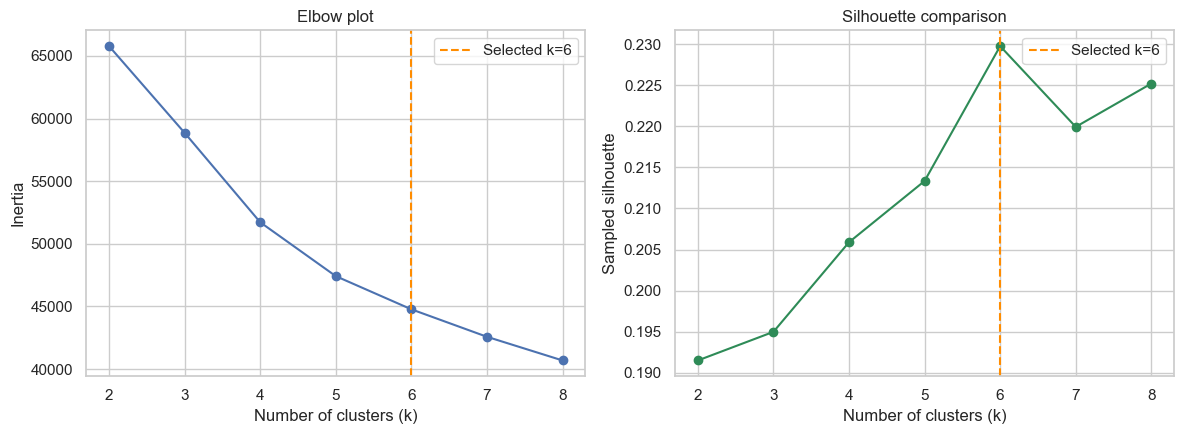

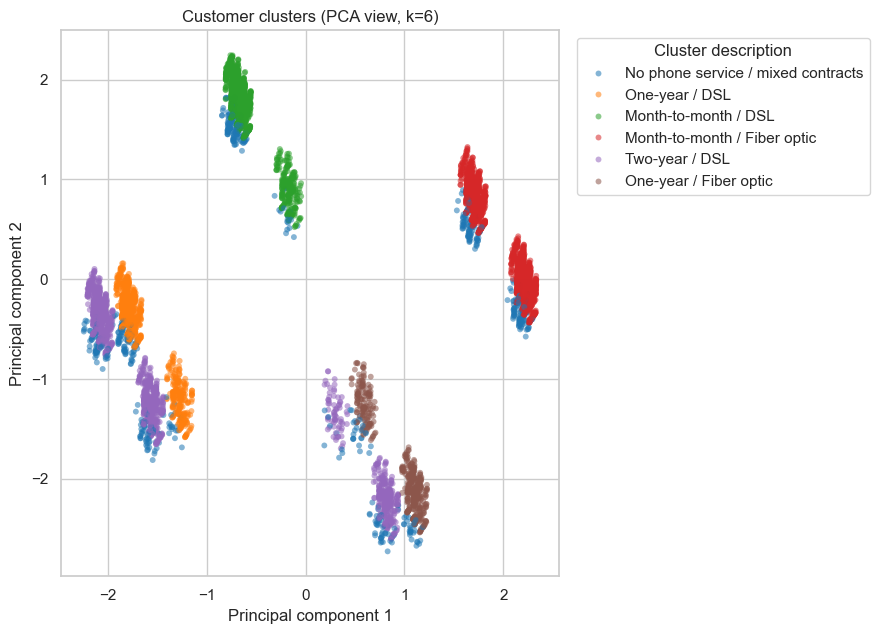

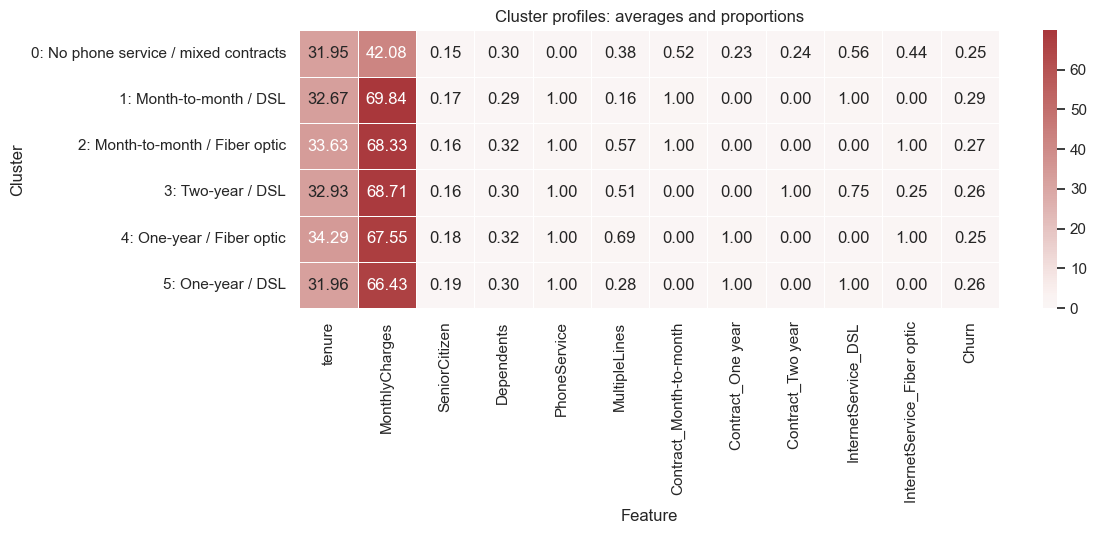

In [6]:
sns.set_theme(style='whitegrid', context='notebook')
output_dir = Path('.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(metrics['k'], metrics['inertia'], marker='o')
axes[0].axvline(best_k, color='darkorange', linestyle='--', label=f'Selected k={best_k}')
axes[0].set(title='Elbow plot', xlabel='Number of clusters (k)', ylabel='Inertia')
axes[0].legend()
axes[1].plot(metrics['k'], metrics['silhouette_sample'], marker='o', color='seagreen')
axes[1].axvline(best_k, color='darkorange', linestyle='--', label=f'Selected k={best_k}')
axes[1].set(title='Silhouette comparison', xlabel='Number of clusters (k)', ylabel='Sampled silhouette')
axes[1].legend()
fig.tight_layout()
fig.savefig(output_dir / 'ats_elbow.png', dpi=180, bbox_inches='tight')
plt.show()

coords = PCA(n_components=2, random_state=random_state).fit_transform(X_scaled)
plot_data = pd.DataFrame({'PC1': coords[:, 0], 'PC2': coords[:, 1], 'cluster_name': result['cluster_name']})
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.scatterplot(data=plot_data, x='PC1', y='PC2', hue='cluster_name', palette='tab10', s=18, alpha=0.55, linewidth=0, ax=ax)
ax.set(title=f'Customer clusters (PCA view, k={best_k})', xlabel='Principal component 1', ylabel='Principal component 2')
ax.legend(title='Cluster description', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(output_dir / 'ats_pca_clusters.png', dpi=180, bbox_inches='tight')
plt.show()

heat_columns = ['tenure', 'MonthlyCharges', 'SeniorCitizen', 'Dependents', 'PhoneService', 'MultipleLines', *contract_columns.values(), *internet_columns.values(), target]
heat = result.groupby('cluster')[heat_columns].mean()
heat.index = [f'{i}: {profile.loc[i, "cluster_name"]}' for i in heat.index]
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='vlag', center=0.5, linewidths=.4, ax=ax)
ax.set(title='Cluster profiles: averages and proportions', xlabel='Feature', ylabel='Cluster')
fig.tight_layout()
fig.savefig(output_dir / 'ats_cluster_profiles.png', dpi=180, bbox_inches='tight')
plt.show()